# Processing the Sarasota wind dataset

Issue #14: Preprocess chlorophyll and wind data from 09/15.

Cleans `SarasotaWindData.csv`, handles missing values and extreme values, and builds daily wind features that can be joined to habsos and the merged chlorophyll data.

| Section | What it covers |
|---|---|
| 1 | What is in the file |
| 2 | Missing values and missing time steps |
| 3 | Grid, longitude and land points |
| 4 | Extreme values |
| 5 | Daily features |
| 6 | Save |
| 7 | What this dataset cannot tell us (no north–south wind) |

**Output:** `data/processed/wind_daily.csv` (one row per water point per day with readings).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from global_land_mask import globe   # pip install global-land-mask

DATA = Path("../data")
WIND_PATH = DATA / "SarasotaWindData.csv"
OUT_POINTS = DATA / "processed" / "wind_daily.csv"

## 1. What is in the file

Row 2 of the CSV is a units row, not data, so it is read separately and skipped.

In [2]:
units = pd.read_csv(WIND_PATH, nrows=1)
wind = pd.read_csv(WIND_PATH, skiprows=[1])
wind["time"] = pd.to_datetime(wind["time"])   # stored as text, e.g. '2019-01-01T00:00:00Z' (UTC)

print("Units:", units.iloc[0].to_dict())
print(f"Rows: {len(wind):,}")
wind.head()

Units: {'time': 'UTC', 'latitude': 'degrees_north', 'longitude': 'degrees_east', 'uwnd': 'm s-1'}
Rows: 549,780


,time,latitude,longitude,uwnd
0,2019-01-01 00:00:00+00:00,26.625,276.625,-4.081281
1,2019-01-01 00:00:00+00:00,26.625,276.875,-3.825571
2,2019-01-01 00:00:00+00:00,26.625,277.125,-3.380656
3,2019-01-01 00:00:00+00:00,26.625,277.375,-2.561112
4,2019-01-01 00:00:00+00:00,26.625,277.625,-1.520360


In [3]:
times = wind.time.drop_duplicates().sort_values()
pd.Series({
    "columns": ", ".join(wind.columns),
    "first time": times.min(),
    "last time": times.max(),
    "time step": times.diff().mode()[0],
    "hours of day (UTC)": sorted(wind.time.dt.hour.unique().tolist()),
    "grid points": wind.groupby(["latitude", "longitude"]).ngroups,
    "rows per (time, point), max": wind.groupby(["time", "latitude", "longitude"]).size().max(),
}, name="value").to_frame()

,value
columns,"time, latitude, longitude, uwnd"
first time,2019-01-01 00:00:00+00:00
last time,2026-09-15 18:00:00+00:00
time step,0 days 06:00:00
hours of day (UTC),"[0, 6, 12, 18]"
grid points,49
"rows per (time, point), max",1


**Takeaway:** one variable, `uwnd`: the **east–west** part of the wind at 10 m, in m/s. Positive = blowing toward the east, negative = toward the west. Values are every 6 hours on a 49-point grid, with no duplicate rows.

The format (variable name `uwnd`, 0.25° grid, 6-hourly, starting 2019) matches the CCMP wind product (Cross-Calibrated Multi-Platform), which blends satellite wind measurements with a weather-model background ([Remote Sensing Systems](https://www.remss.com/measurements/ccmp/), [NASA PO.DAAC](https://podaac.jpl.nasa.gov/dataset/CCMP_WINDS_10M6HR_L4_V3.1)). This is inferred from the format, not confirmed with the data provider.

## 2. Missing values and missing time steps

In [4]:
print("NaN values in uwnd:", int(wind.uwnd.isna().sum()))

expected = pd.date_range(times.min(), times.max(), freq="6h")
missing = expected.difference(pd.DatetimeIndex(times))
print(f"Expected 6-hourly time steps: {len(expected):,} | present: {len(times):,} | missing: {len(missing)}")

missing_days = pd.Series(missing.date).value_counts().sort_index().rename("missing 6-hour steps")
missing_days.rename_axis("date").to_frame()

NaN values in uwnd: 0
Expected 6-hourly time steps: 11,260 | present: 11,220 | missing: 40


,missing 6-hour steps
date,
2020-07-09,4
2020-07-13,4
2020-07-15,4
2020-08-04,4
2020-08-09,4
2020-08-11,4
2020-10-22,4
2020-10-23,4
2021-04-23,4


**Takeaway:** there are **no NaN values**, but **40 six-hour time steps are missing completely** (all 49 points), spread over 10 days. Most of those days are missing all four readings.

**Decision:** leave them missing; don't fill them in. Filling a missing day by interpolating between the day before and the day after would use a future day's wind, which a forecasting model would not have. Section 5 records how many readings each day had (`n_obs`), so days built from fewer readings are visible.

## 3. Grid, longitude and land points

In [5]:
grid = wind[["latitude", "longitude"]].drop_duplicates().sort_values(["latitude", "longitude"]).reset_index(drop=True)
print("Latitude spacing:", np.unique(np.round(np.diff(np.sort(grid.latitude.unique())), 4)),
      "| longitude spacing:", np.unique(np.round(np.diff(np.sort(grid.longitude.unique())), 4)))
print(f"Raw longitude: {grid.longitude.min()} to {grid.longitude.max()}  (0–360 format)")

wind["longitude"] = wind["longitude"] - 360
grid["longitude"] = grid["longitude"] - 360
print(f"Converted longitude: {grid.longitude.min()} to {grid.longitude.max()}  (−180..180, same as habsos)")

Latitude spacing: [0.25] | longitude spacing: [0.25]
Raw longitude: 276.625 to 278.125  (0–360 format)
Converted longitude: -83.375 to -81.875  (−180..180, same as habsos)


Unlike chlorophyll, every grid point has a value at every time, **including points over land**: the product fills in gaps from its weather-model background. Points whose centre is on land are flagged with a 1 km land map (GLOBE, via [`global-land-mask`](https://github.com/toddkarin/global-land-mask)); over-land values are less directly tied to the water.

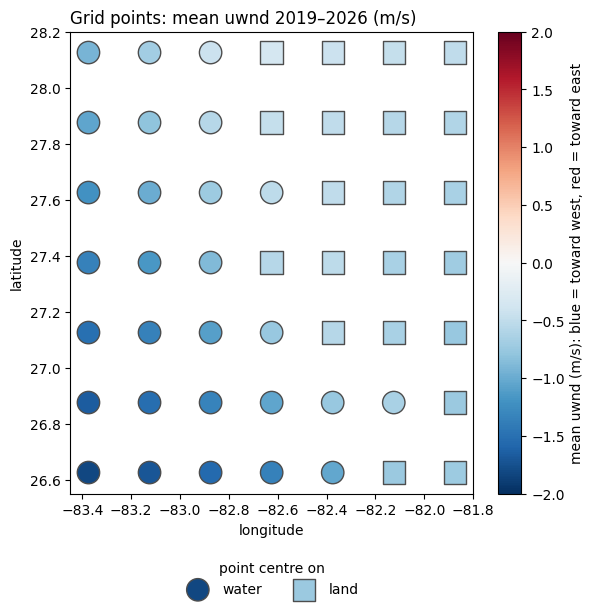

Points on land: 21 of 49


In [6]:
grid["on_land"] = globe.is_land(grid.latitude.values, grid.longitude.values).astype("int8")
wind = wind.merge(grid, on=["latitude", "longitude"])
mean_u = wind.groupby(["latitude", "longitude"]).uwnd.mean().rename("mean_uwnd").reset_index().merge(grid)

fig, ax = plt.subplots(figsize=(6.5, 6))
for flag, marker, label in [(0, "o", "water"), (1, "s", "land")]:
    g = mean_u[mean_u.on_land == flag]
    sc = ax.scatter(g.longitude, g.latitude, c=g.mean_uwnd, cmap="RdBu_r", vmin=-2, vmax=2,
                    s=260, marker=marker, edgecolors="0.3", label=label)
ax.set_xlabel("longitude"); ax.set_ylabel("latitude")
ax.set_title("Grid points: mean uwnd 2019–2026 (m/s)", loc="left")
ax.legend(title="point centre on", loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False)
fig.colorbar(sc, label="mean uwnd (m/s): blue = toward west, red = toward east")
plt.show()
print(f"Points on land: {grid.on_land.sum()} of {len(grid)}")

**Takeaway:** 49 points, 0.25° apart (about 28 km), covering the same box off Sarasota as the chlorophyll data. Longitude is converted to −180..180 to match habsos. Land points are flagged here and dropped in section 5, matching the merged chlorophyll file.

## 4. Extreme values

         count  mean   std    min   0.1%   1%   50%   99%  99.9%    max
uwnd  549780.0 -0.87  3.54 -23.26 -12.15 -9.3 -0.88  7.41  11.52  35.97

IQR rule would flag 4,973 rows (0.9%), anything outside -10.3 to 8.7 m/s


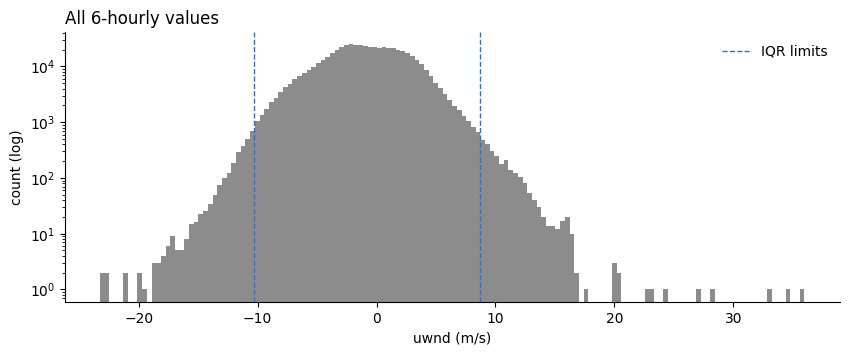

In [7]:
print(wind.uwnd.describe(percentiles=[0.001, 0.01, 0.5, 0.99, 0.999]).round(2).to_frame().T.to_string())

q1, q3 = wind.uwnd.quantile([0.25, 0.75])
lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
iqr_flag = (wind.uwnd < lo) | (wind.uwnd > hi)
print(f"\nIQR rule would flag {iqr_flag.sum():,} rows ({iqr_flag.mean():.1%}), anything outside {lo:.1f} to {hi:.1f} m/s")

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.hist(wind.uwnd, bins=150, color="0.55")
ax.axvline(lo, color="#2a6fdb", ls="--", lw=1); ax.axvline(hi, color="#2a6fdb", ls="--", lw=1, label="IQR limits")
ax.set_yscale("log"); ax.set_xlabel("uwnd (m/s)"); ax.set_ylabel("count (log)")
ax.set_title("All 6-hourly values", loc="left"); ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False); plt.show()

In [8]:
wind["date"] = wind.time.dt.tz_localize(None).dt.normalize()
daily_peak = wind.groupby("date").uwnd.agg(lambda s: s.abs().max()).rename("max |uwnd| across grid (m/s)")
daily_peak.sort_values(ascending=False).head(8).round(1).to_frame()

,max |uwnd| across grid (m/s)
date,
2024-10-10,36.0
2022-09-28,23.3
2022-09-29,20.4
2024-10-09,19.9
2021-07-06,17.4
2021-07-07,17.4
2020-11-11,17.1
2024-08-04,16.8


**Takeaway:** most values sit between about −9 and +7 m/s; the extremes are real storms, not errors.

- **2024-10-10** is Hurricane Milton, which made landfall near Siesta Key on the evening of 9 October 2024 ([NHC report](https://www.nhc.noaa.gov/data/tcr/AL142024_Milton.pdf)). At that time the 49 points range from about −21 to +36 m/s, the circulation around the storm.
- **2022-09-28/29** coincides with Hurricane Ian's landfall to the south of Sarasota.
- Other high days are strong winter cold fronts.

**Decision:** keep every value. The IQR rule would delete the hurricanes, exactly the conditions that move water and blooms.

## 5. Daily features

The other datasets are daily (habsos samples, chlorophyll, CHIRPS), so the 6-hourly values are averaged per point per day. Note that `date` is the **UTC** day (Sarasota is 4–5 hours behind UTC).

| Column | Meaning |
|---|---|
| `uwnd_mean` | mean east–west wind that day (m/s) |
| `uwnd_min`, `uwnd_max` | lowest and highest 6-hourly value that day |
| `n_obs` | how many 6-hourly readings the day had (normally 4) |

In [9]:
daily = (wind.groupby(["latitude", "longitude", "on_land", "date"])
             .uwnd.agg(uwnd_mean="mean", uwnd_min="min", uwnd_max="max", n_obs="count")
             .reset_index())

# full daily calendar per point, so missing days stay as gaps rather than being skipped over
all_days = pd.date_range(daily.date.min(), daily.date.max(), freq="D")
idx = pd.MultiIndex.from_product([grid.latitude.unique(), grid.longitude.unique(), all_days],
                                 names=["latitude", "longitude", "date"])
daily = (daily.set_index(["latitude", "longitude", "date"]).reindex(idx).reset_index()
              .drop(columns="on_land").merge(grid, on=["latitude", "longitude"]))
daily["n_obs"] = daily.n_obs.fillna(0).astype("int8")

print(f"Rows: {len(daily):,} ({len(grid)} points × {len(all_days):,} days)")
print("Days with no readings at all:", int((daily.groupby('date').n_obs.sum() == 0).sum()))
daily.head()

Rows: 137,935 (49 points × 2,815 days)
Days with no readings at all: 10


,latitude,longitude,date,uwnd_mean,uwnd_min,uwnd_max,n_obs,on_land
0,26.625,-83.375,2019-01-01,-3.575797,-4.436267,-1.962274,4,0
1,26.625,-83.375,2019-01-02,-4.060227,-5.108349,-2.575665,4,0
2,26.625,-83.375,2019-01-03,-2.613749,-4.785283,-0.759556,4,0
3,26.625,-83.375,2019-01-04,-0.304013,-2.125544,1.735395,4,0
4,26.625,-83.375,2019-01-05,5.406840,2.177696,7.820418,4,0


### Match the merged chlorophyll file's format

The merged chlorophyll file (`chlorophyll_merged.csv`) follows a few conventions; the wind file now follows the same ones so the two can be used side by side:

| Convention in `chlorophyll_merged.csv` | Applied to wind |
|---|---|
| Land cells dropped | land points dropped (`on_land == 1`) |
| One row per actual observation; no rows for missing days | days with no readings dropped |
| `date` as YYYY-MM-DD, longitude −180..180 | same |

In [10]:
wind_daily = (daily[(daily.on_land == 0) & (daily.n_obs > 0)]
              .drop(columns="on_land")
              .sort_values(["date", "latitude", "longitude"], ignore_index=True))

print(f"Water points kept: {(grid.on_land == 0).sum()} of {len(grid)}")
print(f"Rows: {len(wind_daily):,} | duplicates (date, lat, lon): {wind_daily.duplicated(['date', 'latitude', 'longitude']).sum()} "
      f"| missing uwnd_mean: {wind_daily.uwnd_mean.isna().sum()}")
wind_daily.head()

Water points kept: 28 of 49
Rows: 78,540 | duplicates (date, lat, lon): 0 | missing uwnd_mean: 0


,latitude,longitude,date,uwnd_mean,uwnd_min,uwnd_max,n_obs
0,26.625,-83.375,2019-01-01,-3.575797,-4.436267,-1.962274,4
1,26.625,-83.125,2019-01-01,-3.630455,-4.598077,-2.313720,4
2,26.625,-82.875,2019-01-01,-3.522172,-4.644734,-2.804027,4
3,26.625,-82.625,2019-01-01,-3.016885,-4.451982,-1.954659,4
4,26.625,-82.375,2019-01-01,-2.207515,-3.960940,-0.388318,4


Overview: the east–west wind averaged over all water points, by month:

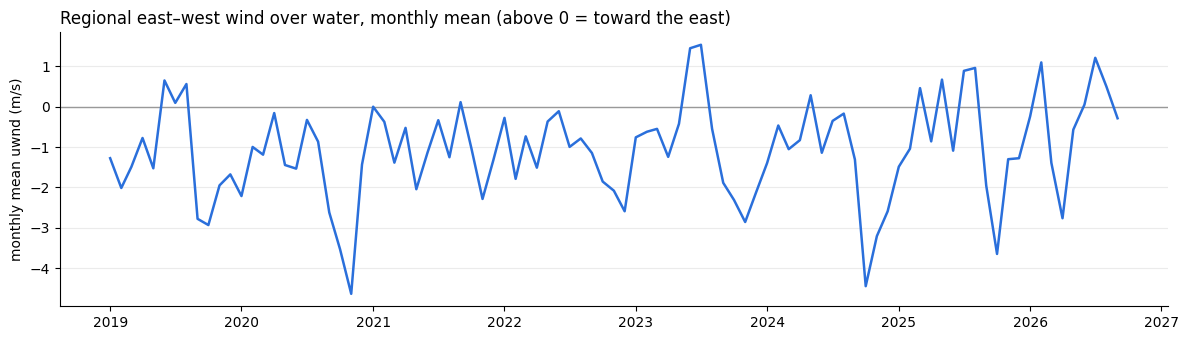

In [11]:
monthly = wind_daily.groupby("date").uwnd_mean.mean().resample("MS").mean()
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.axhline(0, color="0.6", lw=1)
ax.plot(monthly.index, monthly.values, color="#2a6fdb", lw=1.8)
ax.set_ylabel("monthly mean uwnd (m/s)")
ax.set_title("Regional east–west wind over water, monthly mean (above 0 = toward the east)", loc="left")
ax.grid(axis="y", color="0.92"); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## 6. Save

In [12]:
OUT_POINTS.parent.mkdir(parents=True, exist_ok=True)
cols = ["date", "latitude", "longitude", "uwnd_mean", "uwnd_min", "uwnd_max", "n_obs"]
wind_daily[cols].to_csv(OUT_POINTS, index=False, date_format="%Y-%m-%d", float_format="%.3f")
print(f"Saved {len(wind_daily):,} rows to {OUT_POINTS}")

Saved 78,540 rows to ..\data\processed\wind_daily.csv


## 7. What this dataset cannot tell us

`SarasotaWindData` only has `uwnd`, the **east–west** part of the wind. The **north–south** part (`vwnd`) is not in any file we were given, so **wind speed and direction cannot be calculated** from this dataset. A north wind, for example, shows up here as `uwnd ≈ 0`, the same as calm air.

Other sources in the repo, checked:

| Source | Wind information | Limitation |
|---|---|---|
| `Sarasota_Wind&Temp.csv` | wind speed, direction and gusts | one station (Sarasota airport), hourly, Jul 2022 – Jun 2026 only |
| `habsos_cellcounts.csv` | `WIND_SPEED`, `WIND_DIR` columns | almost empty (about 0.1% / 0% filled) |

**Options:** ask the data provider for the matching north–south component (`vwnd`), which the CCMP product publishes alongside `uwnd`; or use the airport station for speed and direction from mid-2022 onward.

## Summary

| Step | Decision |
|---|---|
| Units row, time | Skipped the units row; time converted from text to datetime (UTC) |
| Longitude | Converted from 0–360 to −180..180 to match habsos |
| Missing values | No NaN; 40 six-hour steps (10 days) missing → left missing, `n_obs` records readings per day |
| Land points | Dropped, as in the merged chlorophyll file |
| Extreme values | Kept (hurricanes Milton and Ian, strong fronts); no IQR removal |
| Daily features | Daily mean (`uwnd_mean`), min and max |
| Format | Same conventions as `chlorophyll_merged.csv`: water points only, one row per day with readings, −180..180 longitude |
| Not possible | Wind speed and direction (no `vwnd`) |